# <center>VAI Academy</center>
# <center> Introdução a Machine Learning </center>
___

# <center> Objetivos de aprendizado </center>
- Familiarizar-se com as classes de algoritmos de ML
- Familiarizar-se com alguns termos específicos da Ciência de Dados
- Familiarizar-se com as métricas mais utilizadas na construção de modelos de ML
___

## Conteúdo
1. [Introdução](#intro) <br>
2. [Definição](#def) <br>
3. [Ciclo de Projetos de Data Science](#ciclo) <br>
4. [Classes de algoritmos de ML](#classes) <br>
5. [Aprendizado Supervisionado](#supervised) <br>
6. [Aprendizado Não Supervisionado](#unsupervised) <br>

<a id="dsprecap"></a>

Parte do conteúdo dessa aula também está disponível em formato de vídeo. Os vídeos já estão inseridos no notebook e aparecem no mesmo ao rodar as células com a função ```YouTubeVideo```, como a próxima.

<a id='unsupervised'></a>
## 6. Aprendizado Não Supervisionado



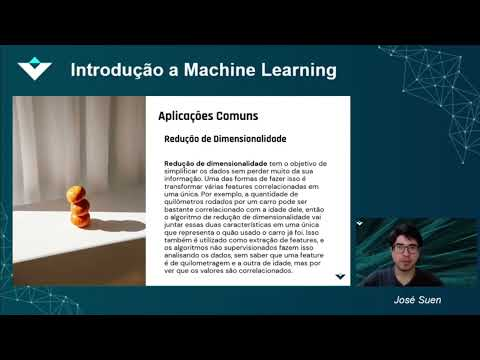

In [1]:
from IPython.display import YouTubeVideo
YouTubeVideo('SdnExUS5ko0', width = 640, height = 360)

Nas seções anteriores estávamos lidando com dados que tinham rótulos associados a eles.
Quando rotulamos os dados de treino, os algoritmos aprendem a classificar os dados com base naqueles rótulos. Mas, no mundo real nem sempre temos acesso aos dados rotulados. <br>

Às vezes temos somente muitos dados e precisamos categorizá-los de alguma forma. É aqui que o aprendizado não supervisionado
pode ser utilizado. Algoritmos de aprendizagem não supervisionada tentam construir modelos que podem encontrar subgrupos dentro de um determinado conjunto de dados usando alguma métrica de similaridade.

Cada grupo é conhecido como **clusters**. Basicamente, o objetivo é segmentar grupos com características semelhantes e distribuí-los em grupos.

### 6.1 Exemplo de algoritmo: K-means

O algoritmo K-means foi proposto como uma forma de **agrupar dados semelhantes em clusters**, a partir de uma grande quantidade de dados. Como veremos abaixo, o algoritmo k-means é extremamente fácil de ser implementado, mas também é computacionalmente muito eficiente quando comparado com outros algoritmos de *clusterização*, o que explica sua popularidade.

Este algoritmo pertence à categoria de **prototype-based clustering**. Isso significa que cada cluster é representado por um protótipo, que pode tanto ser o **centróide (média)** de pontos semelhantes, ou o **medóide** (o ponto mais representativo ou de ocorrência mais frequente) no caso de variáveis categóricas. Embora o k-means seja muito bom para identificar grupos de forma esférica, uma das desvantagens deste algoritmo de agrupamento é que temos que especificar o número de clusters k a priori.

Uma escolha inadequada de $ k $ pode resultar em um agrupamento ruim.

#### Exemplo prático 2

Apenas para mostrar um exemplo, o código abaixo vai gerar pontos aleatórios centrados em alguns pontos utilizando a função ```make_blobs``` do sklearn.
Podemos definir a quantidade de pontos, o número de centros e a dispersão desses pontos gerados. Brinque um pouco com esses valores para ver como os pontos variam. Depois, utilizaremos o k-means para agrupar esses pontos.

In [3]:
n_pontos = 200
n_centros = 4
dispersao = 0.5

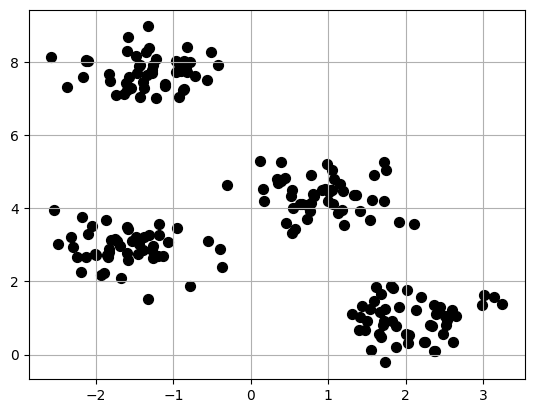

In [4]:
%matplotlib inline
from sklearn.datasets import make_blobs
import matplotlib.pyplot as plt

X,y = make_blobs(n_samples=n_pontos,
                 n_features=2,
                 centers=n_centros,
                 cluster_std=dispersao,
                 shuffle=True,
                 random_state=0)

plt.scatter(X[:,0],
            X[:,1],
            c='black',
            marker='o',
            s=50)

plt.grid()
plt.show()

Agora utilizamos o método de k-means para agrupar os pontos em N clusters.
Tente alterar o valor de N e avaliar o que acontece.

In [12]:
# Altere o numero de clusters aqui
N = 4

/usr/local/lib/python3.10/dist-packages/sklearn/cluster/_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(


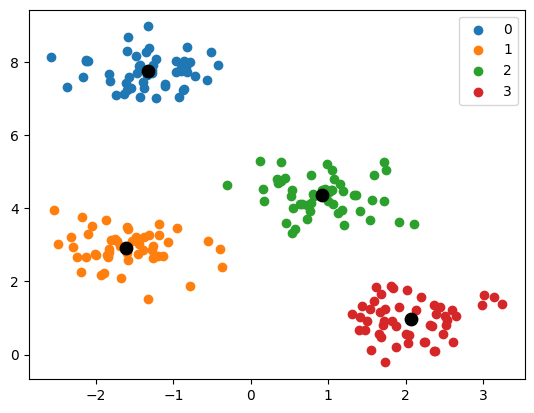

In [13]:
from sklearn.cluster import KMeans
import numpy as np
import pandas as pd

#Create KMeans object
km = KMeans(n_clusters=N)

#Perform K-means clusterization
cluster_km = km.fit_predict(X)

df = pd.DataFrame({'x':[x[0] for x in X],
                   'y':[x[1] for x in X],
                   'label':y,
                   'cluster':cluster_km})

unique_clusters = np.unique(cluster_km)
centroids = km.cluster_centers_

# Colocando os clusters nos gráficos
for i in unique_clusters:
    plt.scatter(df[df['cluster'] == i]['x'] , df[df['cluster'] == i]['y'] , label = i)
plt.scatter(centroids[:,0] , centroids[:,1] , s = 80, color = 'k')
plt.legend()
plt.show()

### 6.2 Aplicações comuns

Como encontrar a estrutura que define um conjunto de dados? Como resumí-los e agrupa-los de forma útil? Como comprimir os dados sem perder informação? Essas são algumas das principais perguntas que o aprendizado não supervisionado pode ajudar a responder.

#### 6.2.1 Segmentação de Clientes



Imagine que você tem muitos dados sobre a visita ao site da sua empresa. Você pode tentar identificar grupos similares entre os visitantes, mas em nenhum momento você define esses grupos e passa eles ao algoritmo: ele acha essas conexões e agrupa a partir dos dados.

Você pode obter como resultado, por exemplo, que 40% dos seus visitantes são mulheres de uma parte específica do país, que 20% são pessoas jovens que acessam o seu site toda semana, e assim vai.

#### 6.2.2 Deteção de Anomalia/Outliers



Outra aplicação importante do aprendizado não supervisionado é a detecção de anomalia. Por exemplo, identificar transações incomuns nos cartões de crédito para prevenir fraudes, verificar erros em processos de produção ou remover casos de *outliers* antes de utilizar os dados em um modelo. Basicamente, o sistema compara as observações passadas e identifica aquelas que mais diferem do resto da amostra, que são mais prováveis de serem anomalias.

**Algoritmos mais comuns para essa tarefa:**

* [K-means](https://towardsdatascience.com/k-means-explained-10349949bd10)
* [Hierarchical Clustering](https://towardsdatascience.com/hierarchical-clustering-explained-e58d2f936323)
* [Isolation Forest](https://towardsdatascience.com/outlier-detection-with-isolation-forest-3d190448d45e)

#### 6.2.3 Visualização e Redução de Dimensionalidade



**Algoritmos de visualização** também são bons exemplos de algoritmos de aprendizado não supervisionado: você dá para o algoritmo uma grande quantidade de dados complexos e não classificados, e ele te retorna um gráfico em duas ou três dimensões que podem ser facilmente colocados num gráfico.
Esses algortimos tentam preservar ao máximo a estrutura de dados (por exemplo, garantindo que grupos que sejam diferentes nos dados de entrada também estejam distantes no gráfico), para que você consiga entender como o dado está organizado e talvez até identificar alguns padrões.

**Redução de dimensionalidade** tem o objetivo de simplificar os dados sem perder muito da sua informação. Uma das formas de fazer isso é transformar várias *features* correlacionadas em uma única. Por exemplo, a quantidade de quilômetros rodados por um carro pode ser bastante correlacionado com a idade dele, então o algoritmo de redução de dimensionalidade vai juntar essas duas características em uma única que representa o quão usado o carro já foi. Isso também é utilizado como **extração de features**, e os algoritmos não supervisionados fazem isso analisando os dados, sem saber que uma *feature* é de quilometragem e a outra de idade, mas por ver que os valores são correlacionados.

Tentar reduzir a dimensionalidade dos dados de treinamento dos modelos (por exemplo, supervisionados) usando **algoritmos de redução de dimensionalidade** normalmente é uma boa ideia. Isso vai fazer com que o treino seja muito mais rápido, os dados vão ocupar menos espaço em disco e em memória, e em alguns casos pode até ter uma performance melhor.

**Algoritmos mais comuns para essa tarefa:**

* [Principal Component Analysis (PCA)](https://towardsdatascience.com/principal-component-analysis-pca-explained-visually-with-zero-math-1cbf392b9e7d#:~:text=Principal%20component%20analysis%20(PCA)%20is%20a%20technique%20that%20transforms%20high,and%20third%20principal%20components%2C%20respectively.)
* [T-distributed Stochastic Neighbor Embedding (t-SNE)](https://towardsdatascience.com/t-sne-clearly-explained-d84c537f53a)

A animação abaixo representa o **processo do t-SNE** de agrupar palavras similares do Google News. Esse método reduz a dimensionalidade dos dados. Nesse caso, reduz de 200 para 2, para que você consiga vê-los em um gráfico com significado.

![image.png](https://cdn-images-1.medium.com/max/1120/0*OFEG6lda-nRTLVYs)

# Declaração de Inexistência de Plágio:

1. Eu sei que plágio é utilizar o trabalho de outra pessoa e apresentar como meu.
2. Eu sei que plágio é errado e declaro que este notebook foi feito por mim.
3. Tenho consciência de que a utilização do trabalho de terceiros é antiético e está sujeito a medidas administrativas.
4. Declaro também que não compartilhei e não compartilharei meu trabalho com o intuito de que seja copiado e submetido por outra pessoa.

In [14]:
# LEMBRE-SE DE SALVAR O NOTEBOOK ANTES DE EXECUTAR ESSA CÉLULA
token = '' # seu token aqui

# Não altere o código abaixo
import requests as req
%matplotlib
exec(req.get('https://api.vai.academy/submissioncode2').text)
%matplotlib inline

Using matplotlib backend: <object object at 0x7ccfdf20f6b0>
Importante: lembre-se de salvar o notebook antes de rodar esta célula!
Executando o seu notebook para a submissão. Isso pode demorar alguns instantes...
>> Verificando exercicios para correção... 


/usr/local/lib/python3.10/dist-packages/sklearn/cluster/_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(


>> Submetendo exercício 2... "Score: 1/1"

Tentativa de submissao #1 / 30
Aluno: Larissa Coelho Ramos
Score: 1 / 1
Parabéns!! Você atingiu os critérios para passar neste notebook.

Pontuação por exercício
Exercicio  Pontuacao Maxima  Pontuacao Obtida
        2                 1                 1



# Fim da Aula!